1. Desarrollar una función basada en ciclos que permita
detectar puntos aislados en una imagen. Verificar el
funcionamiento con la imagen "Liraimpulsivo.pgm".
Eliminar el término promedio (1/9), ejecutar de nuevo
el programa, observar y concluir.

2. Desarrollar una función basada en ciclos que permita
detectar líneas horizontales, verticales y diagonales
en una imagen. Verificar el funcionamiento con la
imagen "FormasRuido.pgm". Establecer un umbral
apropiado para visualizar solo trazos deseados.

3. Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando la máscara
Prewitt. Verificar el funcionamiento con la imagen
"Gwen.pgm" y otras imágenes.

4. Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando la máscara
Sobel. Verificar el funcionamiento con las mismas
imágenes del punto anterior.

5. Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando la máscara
Laplaciano. Verificar el funcionamiento con la imagen
"Gwen.pgm" y otras imágenes.

6. Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando el algoritmo
de Marr Hildreth. Verificar el funcionamiento con las
mismas imágenes del punto anterior.

7. Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando la máscara
Canny. Verificar el funcionamiento con la imagen
"Gwen.pgm" y otras imágenes. Utilizar sigma = 5.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

## Punto 1. 
Desarrollar una función basada en ciclos que permita
detectar puntos aislados en una imagen. Verificar el
funcionamiento con la imagen "Liraimpulsivo.pgm".
Eliminar el término promedio (1/9), ejecutar de nuevo
el programa, observar y concluir.

In [23]:
# Imagen sintética de 32x32 con fondo gris
imagen_prueba = np.full((32, 32), 50, dtype=np.uint8)

# Dos puntos brillantes
imagen_prueba[8, 8] = 255
imagen_prueba[16, 24] = 230

# Un punto oscuro
imagen_prueba[24, 12] = 0

# Cargar imagen real en escala de grises
imagen_estrellas = cv2.imread(
    "images/CampoEstrellas.png",
    cv2.IMREAD_GRAYSCALE
)

if imagen_estrellas is None:
    raise FileNotFoundError("No se encontró CampoEstrellas.png")

In [25]:
def detectar_puntos_aislados(imagen, umbral, usar_promedio=True):

    if imagen is None:
        raise ValueError("La imagen no se cargó correctamente.")

    if umbral < 0:
        raise ValueError("El umbral no puede ser negativo.")

    # Dimensiones de la imagen
    filas, columnas = imagen.shape

    # Matriz de respuestas con signo
    respuestas = np.zeros(
        (filas, columnas),
        dtype=np.float64
    )

    # Imagen binaria de puntos detectados
    puntos_detectados = np.zeros(
        (filas, columnas),
        dtype=np.uint8
    )

    # Máscara espacial 3x3
    mascara = np.array([
        [-1, -1, -1],
        [-1,  8, -1],
        [-1, -1, -1]
    ], dtype=np.float64)

    # Aplicar el factor 1/9 si corresponde
    if usar_promedio:
        mascara = mascara / 9.0

    # Recorrer la imagen evitando sus bordes
    for fila in range(1, filas - 1):
        for columna in range(1, columnas - 1):

            suma = 0.0

            # Recorrer la máscara 3x3
            for i in range(-1, 2):
                for j in range(-1, 2):

                    pixel = float(imagen[fila + i, columna + j])
                    peso = mascara[i + 1, j + 1]

                    suma += pixel * peso

            # Guardar respuesta del filtro
            respuestas[fila, columna] = suma

            # Aplicar umbral al valor absoluto
            if abs(suma) > umbral:
                puntos_detectados[fila, columna] = 255

    return respuestas, puntos_detectados

Respuesta en (8, 8): 1640.0
Respuesta en (16, 24): 1440.0
Respuesta en (24, 12): -400.0


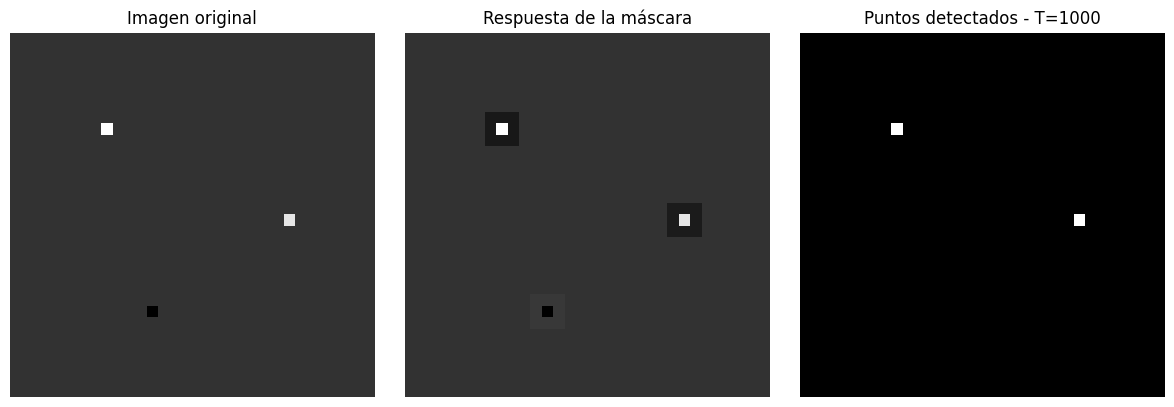

In [26]:
respuestas, puntos = detectar_puntos_aislados(
    imagen_prueba,
    umbral=1000,
    usar_promedio=False
)

print("Respuesta en (8, 8):", respuestas[8, 8])
print("Respuesta en (16, 24):", respuestas[16, 24])
print("Respuesta en (24, 12):", respuestas[24, 12])

fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(
    imagen_prueba,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)
axs[0].set_title("Imagen original")

axs[1].imshow(
    respuestas,
    cmap="gray",
    interpolation="nearest"
)
axs[1].set_title("Respuesta de la máscara")

axs[2].imshow(
    puntos,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)
axs[2].set_title("Puntos detectados - T=1000")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.savefig("results/deteccion_puntos_aislados.png", dpi=300)
plt.show()

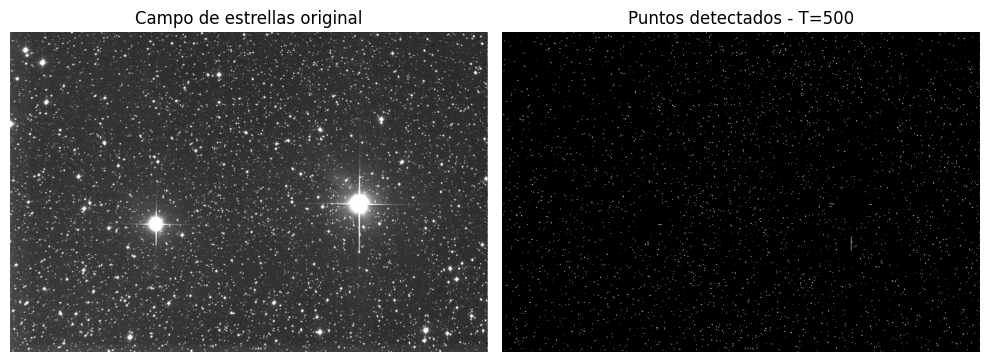

In [27]:
respuestas_estrellas, puntos_estrellas = detectar_puntos_aislados(
    imagen_estrellas,
    umbral=500,
    usar_promedio=False
)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

axs[0].imshow(
    imagen_estrellas,
    cmap="gray",
    vmin=0,
    vmax=255
)
axs[0].set_title("Campo de estrellas original")

axs[1].imshow(
    puntos_estrellas,
    cmap="gray",
    vmin=0,
    vmax=255
)
axs[1].set_title("Puntos detectados - T=500")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.savefig("results/deteccion_puntos_estrellas.png", dpi=300)
plt.show()

Detecciones con factor 1/9: 0
Detecciones sin factor 1/9: 6797


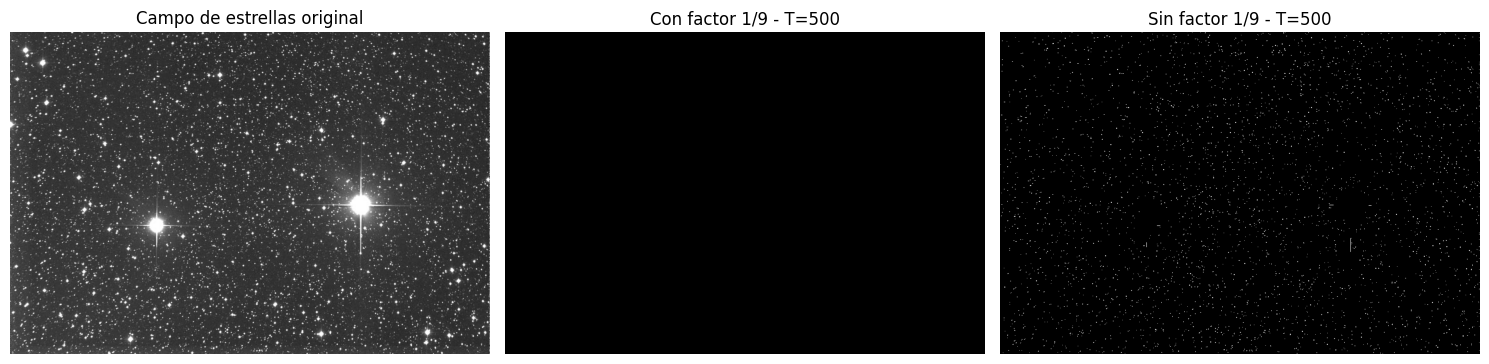

In [29]:
umbral = 500

# Con factor 1/9
respuesta_con, puntos_con = detectar_puntos_aislados(
    imagen_estrellas,
    umbral=umbral,
    usar_promedio=True
)

# Sin factor 1/9
respuesta_sin, puntos_sin = detectar_puntos_aislados(
    imagen_estrellas,
    umbral=umbral,
    usar_promedio=False
)

# Contar píxeles detectados
cantidad_con = np.count_nonzero(puntos_con)
cantidad_sin = np.count_nonzero(puntos_sin)

print("Detecciones con factor 1/9:", cantidad_con)
print("Detecciones sin factor 1/9:", cantidad_sin)

# Visualizar la comparación
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

imagenes_comparacion = [
    imagen_estrellas,
    puntos_con,
    puntos_sin
]

titulos_comparacion = [
    "Campo de estrellas original",
    "Con factor 1/9 - T=500",
    "Sin factor 1/9 - T=500"
]

for ax, img, titulo in zip(
    axs, imagenes_comparacion, titulos_comparacion
):
    ax.imshow(
        img,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.savefig("results/deteccion_estrellas_comparacion.png", dpi=300)
plt.show()

### Análisis de resultados — Detección de puntos aislados

Se implementó una función mediante ciclos para detectar puntos aislados utilizando una máscara espacial de 3×3. El algoritmo compara la intensidad de cada píxel con sus ocho vecinos y utiliza un umbral para determinar cuáles respuestas representan diferencias importantes.

Primero se probó con una imagen sintética de 32×32 píxeles que contenía dos puntos brillantes y uno oscuro. Con un umbral de 1000, se detectaron los dos puntos brillantes, mientras que el punto oscuro no superó dicho valor. También se observó que la máscara genera respuestas positivas o negativas dependiendo de la intensidad del píxel respecto a sus vecinos.

Después se aplicó el algoritmo a una fotografía de un campo de estrellas, utilizando un umbral de 500.

Para cumplir con la comparación solicitada en el taller, se ejecutó el algoritmo utilizando la máscara con el factor \(1/9\) y posteriormente sin este factor, manteniendo el mismo umbral.

Con el factor \(1/9\) no se detectaron píxeles, mientras que sin él se obtuvieron 6797 detecciones. Esto ocurre porque eliminar dicho factor aumenta nueve veces la magnitud de las respuestas, permitiendo que más posiciones superen el umbral.

Sin embargo, estas detecciones no representan necesariamente estrellas individuales, ya que también pueden corresponder a ruido y otras variaciones de intensidad.

**En conclusión**, el algoritmo permite identificar píxeles que presentan diferencias importantes respecto a su entorno. La comparación mostró que el factor \(1/9\) modifica la escala de las respuestas y que la cantidad de detecciones depende del umbral seleccionado.

## Punto 2. 
Desarrollar una función basada en ciclos que permita
detectar líneas horizontales, verticales y diagonales
en una imagen. Verificar el funcionamiento con la
imagen "FormasRuido.pgm". Establecer un umbral
apropiado para visualizar solo trazos deseados.

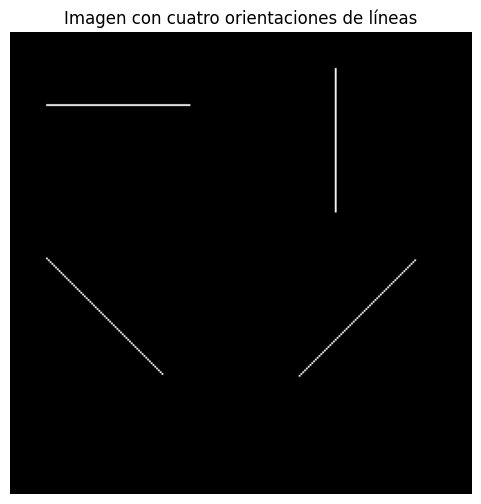

In [30]:
imagen_lineas = np.zeros((256, 256), dtype=np.uint8)

# Línea horizontal
imagen_lineas[40, 20:100] = 255

# Línea vertical
imagen_lineas[20:100, 180] = 255

# Diagonal descendente (\)
for i in range(65):
    imagen_lineas[125 + i, 20 + i] = 255

# Diagonal ascendente (/)
for i in range(65):
    imagen_lineas[190 - i, 160 + i] = 255

plt.figure(figsize=(6, 6))
plt.imshow(imagen_lineas, cmap="gray", vmin=0, vmax=255)
plt.title("Imagen con cuatro orientaciones de líneas")
plt.axis("off")
plt.show()

In [31]:
def detectar_lineas(imagen, mascara, umbral):

    if imagen is None:
        raise ValueError("La imagen no se cargó correctamente.")

    if umbral < 0:
        raise ValueError("El umbral no puede ser negativo.")

    filas, columnas = imagen.shape

    respuestas = np.zeros(
        (filas, columnas),
        dtype=np.float64
    )

    lineas_detectadas = np.zeros(
        (filas, columnas),
        dtype=np.uint8
    )

    # Recorrer la imagen evitando bordes
    for fila in range(1, filas - 1):
        for columna in range(1, columnas - 1):

            suma = 0.0

            # Recorrer máscara 3x3
            for i in range(-1, 2):
                for j in range(-1, 2):

                    pixel = float(
                        imagen[fila + i, columna + j]
                    )

                    peso = mascara[i + 1, j + 1]

                    suma += pixel * peso

            respuestas[fila, columna] = suma

            if suma > umbral:
                lineas_detectadas[fila, columna] = 255

    return respuestas, lineas_detectadas

In [32]:
mascaras_lineas = {
    "Horizontal": np.array([
        [-1, -1, -1],
        [ 2,  2,  2],
        [-1, -1, -1]
    ]),

    "Vertical": np.array([
        [-1,  2, -1],
        [-1,  2, -1],
        [-1,  2, -1]
    ]),

    "Diagonal descendente": np.array([
        [ 2, -1, -1],
        [-1,  2, -1],
        [-1, -1,  2]
    ]),

    "Diagonal ascendente": np.array([
        [-1, -1,  2],
        [-1,  2, -1],
        [ 2, -1, -1]
    ])
}

resultados_lineas = {}

for nombre, mascara in mascaras_lineas.items():

    respuestas, detecciones = detectar_lineas(
        imagen_lineas,
        mascara,
        umbral=700
    )

    resultados_lineas[nombre] = detecciones

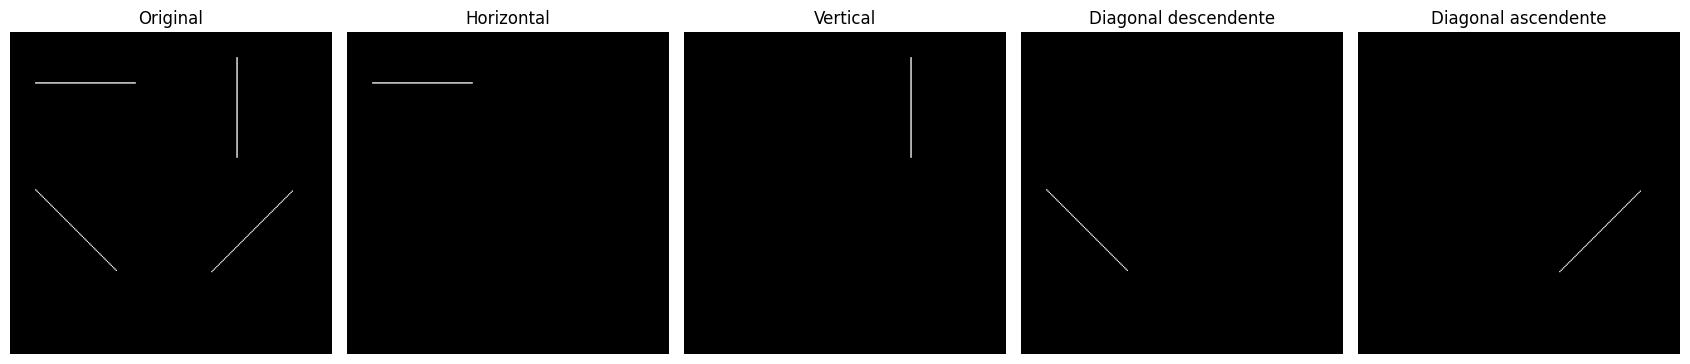

In [33]:
fig, axs = plt.subplots(1, 5, figsize=(17, 4))

axs[0].imshow(
    imagen_lineas,
    cmap="gray",
    vmin=0,
    vmax=255
)
axs[0].set_title("Original")
axs[0].axis("off")

for i, (nombre, detecciones) in enumerate(
    resultados_lineas.items()
):
    axs[i + 1].imshow(
        detecciones,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axs[i + 1].set_title(nombre)
    axs[i + 1].axis("off")

plt.tight_layout()
plt.savefig(
    "results/deteccion_lineas.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [34]:
posiciones = {
    "Horizontal": (40, 60),
    "Vertical": (60, 180),
    "Diagonal descendente": (155, 50),
    "Diagonal ascendente": (160, 190)
}

for nombre, mascara in mascaras_lineas.items():

    respuestas, detecciones = detectar_lineas(
        imagen_lineas,
        mascara,
        umbral=700
    )

    fila, columna = posiciones[nombre]

    print(f"{nombre}:")
    print("Respuesta:", respuestas[fila, columna])
    print("Detectado:", detecciones[fila, columna] == 255)
    print()

Horizontal:
Respuesta: 1530.0
Detectado: True

Vertical:
Respuesta: 1530.0
Detectado: True

Diagonal descendente:
Respuesta: 1530.0
Detectado: True

Diagonal ascendente:
Respuesta: 1530.0
Detectado: True



### Análisis de resultados — Punto 2: Detección de líneas

Se implementó una función basada en cuatro ciclos anidados para detectar líneas mediante máscaras espaciales de 3×3. Se utilizaron cuatro máscaras orientadas a identificar líneas horizontales, verticales y diagonales en ambas direcciones.

Para comprobar el funcionamiento del algoritmo, se creó una imagen sintética de 256×256 píxeles con cuatro líneas blancas de un píxel de grosor sobre fondo negro, cada una con una orientación diferente.

Al aplicar las máscaras, se observó que cada una resaltó correctamente la línea correspondiente a su orientación, mientras que las demás líneas fueron descartadas mediante el umbral establecido.

Se utilizó un umbral de 700 y se verificaron las respuestas en el centro de cada línea. En los cuatro casos se obtuvo un valor de 1530, superando el umbral y confirmando las detecciones.

Esto ocurre porque los coeficientes positivos de cada máscara coinciden con los píxeles que forman la línea buscada, mientras que los coeficientes negativos permiten comparar esa estructura con los píxeles de su entorno.

**En conclusión**, las máscaras espaciales permiten detectar líneas según su orientación mediante diferencias de intensidad. Los resultados confirmaron que la ubicación de los coeficientes positivos y negativos determina a qué tipo de línea responde cada filtro.

## Punto 3
Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando la máscara
Prewitt. Verificar el funcionamiento con la imagen
"Gwen.pgm" y otras imágenes.


In [35]:
def detectar_bordes_prewitt(imagen):

    if imagen is None:
        raise ValueError("La imagen no se cargó correctamente.")

    filas, columnas = imagen.shape

    # Máscaras de Prewitt
    mascara_x = np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1]
    ])

    mascara_y = np.array([
        [-1, -1, -1],
        [ 0,  0,  0],
        [ 1,  1,  1]
    ])

    # Guardar respuestas del gradiente
    gradiente_x = np.zeros((filas, columnas), dtype=np.float64)
    gradiente_y = np.zeros((filas, columnas), dtype=np.float64)

    # Recorrer imagen evitando los bordes
    for fila in range(1, filas - 1):
        for columna in range(1, columnas - 1):

            suma_x = 0.0
            suma_y = 0.0

            # Recorrer las máscaras 3x3
            for i in range(-1, 2):
                for j in range(-1, 2):

                    pixel = float(imagen[fila + i, columna + j])

                    suma_x += pixel * mascara_x[i + 1, j + 1]
                    suma_y += pixel * mascara_y[i + 1, j + 1]

            gradiente_x[fila, columna] = suma_x
            gradiente_y[fila, columna] = suma_y

    # Calcular la magnitud del gradiente
    magnitud = np.sqrt(gradiente_x**2 + gradiente_y**2)

    return magnitud, gradiente_x, gradiente_y

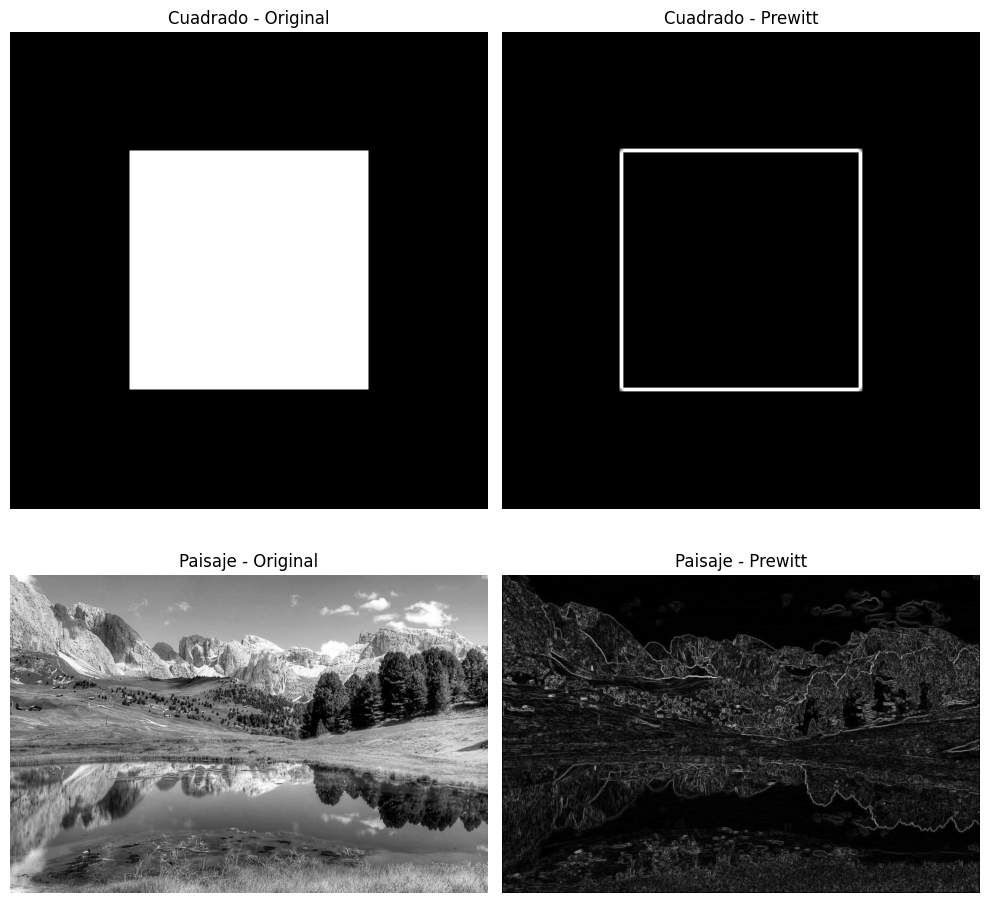

In [42]:
# Cuadrado sintético
cuadrado = np.zeros((256, 256), dtype=np.uint8)
cuadrado[64:192, 64:192] = 255

# Paisaje en escala de grises
paisaje = cv2.imread(
    "images/paisaje.png",
    cv2.IMREAD_GRAYSCALE
)

imagenes_prewitt = [cuadrado, paisaje]
titulos_prewitt = ["Cuadrado", "Paisaje"]

fig, axs = plt.subplots(2, 2, figsize=(10, 10))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos_prewitt, imagenes_prewitt)
):

    magnitud, gx, gy = detectar_bordes_prewitt(imagen_actual)

    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")
    axs[i, 0].axis("off")

    axs[i, 1].imshow(
        magnitud,
        cmap="gray"
    )
    axs[i, 1].set_title(f"{titulo} - Prewitt")
    axs[i, 1].axis("off")

plt.tight_layout()
plt.savefig(
    "results/deteccion_bordes_prewitt.png",
    dpi=300
)
plt.show()

### Análisis de resultados — Punto 3: Detección de bordes mediante Prewitt

Se implementó el operador Prewitt mediante cuatro ciclos anidados, utilizando dos máscaras espaciales de 3×3 para calcular los cambios de intensidad en las direcciones horizontal y vertical. Posteriormente, se combinaron ambas respuestas mediante la magnitud del gradiente.

El algoritmo se probó con dos imágenes en escala de grises: un cuadrado blanco sobre fondo negro y un paisaje natural.

En la imagen del **cuadrado**, se detectaron correctamente sus cuatro bordes, conservando la forma de la figura. Tanto el interior como el fondo permanecieron oscuros, debido a que estas regiones presentan intensidades uniformes. Las respuestas más elevadas se concentraron en las transiciones entre blanco y negro.

En el **paisaje**, el operador resaltó los contornos de las montañas, los árboles, la vegetación y sus reflejos en el agua. También se detectaron pequeñas variaciones de intensidad relacionadas con texturas del terreno y algunas nubes, mientras que las zonas más uniformes del cielo y del lago permanecieron relativamente oscuras.

Los resultados muestran que Prewitt permite identificar bordes mediante los cambios de intensidad de los píxeles. Sin embargo, también responde a detalles y texturas, por lo que no diferencia automáticamente entre los límites principales de los objetos y las variaciones pequeñas.

**En conclusión**, el operador Prewitt permitió detectar correctamente los contornos del cuadrado y destacar numerosas estructuras del paisaje, comprobando que la combinación de gradientes horizontales y verticales permite identificar bordes con diferentes orientaciones.

## Punto 4. 
Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando la máscara
Sobel. Verificar el funcionamiento con las mismas
imágenes del punto anterior.

In [37]:
def detectar_bordes_sobel(imagen):

    if imagen is None:
        raise ValueError("La imagen no se cargó correctamente.")

    filas, columnas = imagen.shape

    # Máscaras de Sobel
    mascara_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])

    mascara_y = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ])

    gradiente_x = np.zeros(
        (filas, columnas), dtype=np.float64
    )

    gradiente_y = np.zeros(
        (filas, columnas), dtype=np.float64
    )

    # Recorrer la imagen
    for fila in range(1, filas - 1):
        for columna in range(1, columnas - 1):

            suma_x = 0.0
            suma_y = 0.0

            # Aplicar ambas máscaras 3x3
            for i in range(-1, 2):
                for j in range(-1, 2):

                    pixel = float(
                        imagen[fila + i, columna + j]
                    )

                    suma_x += pixel * mascara_x[i + 1, j + 1]
                    suma_y += pixel * mascara_y[i + 1, j + 1]

            gradiente_x[fila, columna] = suma_x
            gradiente_y[fila, columna] = suma_y

    # Magnitud del gradiente
    magnitud = np.sqrt(
        gradiente_x**2 + gradiente_y**2
    )

    return magnitud, gradiente_x, gradiente_y

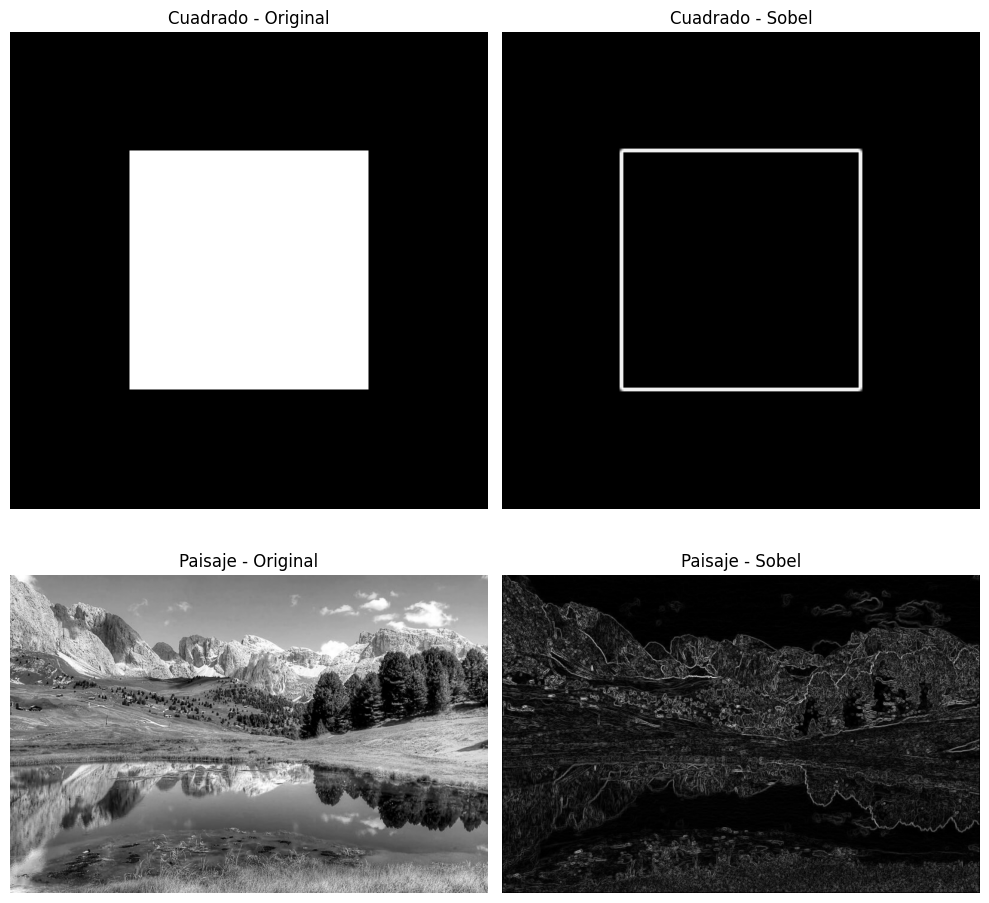

In [41]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos_prewitt, imagenes_prewitt)
):

    magnitud, gx, gy = detectar_bordes_sobel(
        imagen_actual
    )

    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")
    axs[i, 0].axis("off")

    axs[i, 1].imshow(
        magnitud,
        cmap="gray"
    )
    axs[i, 1].set_title(f"{titulo} - Sobel")
    axs[i, 1].axis("off")

plt.tight_layout()
plt.savefig(
    "results/deteccion_bordes_sobel.png",
    dpi=300
)
plt.show()

### Análisis de resultados — Punto 4: Detección de bordes mediante Sobel

Se implementó el operador Sobel mediante cuatro ciclos anidados, utilizando dos máscaras espaciales de 3×3 para calcular los gradientes horizontal y vertical. Posteriormente, se combinaron ambas respuestas mediante la magnitud del gradiente.

El algoritmo se aplicó a las mismas dos imágenes del punto anterior: un cuadrado blanco sobre fondo negro y un paisaje natural.

En la imagen del **cuadrado**, se detectaron correctamente sus cuatro bordes, mientras que el interior y el fondo permanecieron oscuros. Visualmente, el resultado es prácticamente igual al obtenido con Prewitt, debido a que ambos operadores identifican los cambios bruscos de intensidad en las mismas posiciones.

En el **paisaje**, se resaltaron los contornos de las montañas, los árboles, la vegetación y sus reflejos en el agua. También se detectaron numerosas texturas y pequeñas variaciones de intensidad. Al comparar visualmente con Prewitt, las diferencias son poco evidentes, aunque algunos bordes parecen ligeramente más resaltados.

La principal diferencia matemática es que Sobel utiliza coeficientes de mayor peso en la fila o columna central de sus máscaras. Por esta razón, puede generar respuestas de diferente magnitud, aunque los contornos detectados sean similares.

**En conclusión**, el operador Sobel permitió identificar correctamente los bordes de ambas imágenes. Los resultados muestran que Sobel y Prewitt producen detecciones visualmente parecidas en estas pruebas, por lo que no se observó una mejora considerable al utilizar uno sobre el otro.

## Punto5. 
Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando la máscara
Laplaciano. Verificar el funcionamiento con la imagen
"Gwen.pgm" y otras imágenes.

In [43]:
def detectar_bordes_laplaciano(imagen):

    if imagen is None:
        raise ValueError("La imagen no se cargó correctamente.")

    filas, columnas = imagen.shape

    mascara = np.array([
        [0,  1, 0],
        [1, -4, 1],
        [0,  1, 0]
    ])

    respuestas = np.zeros(
        (filas, columnas),
        dtype=np.float64
    )

    for fila in range(1, filas - 1):
        for columna in range(1, columnas - 1):

            suma = 0.0

            for i in range(-1, 2):
                for j in range(-1, 2):

                    pixel = float(
                        imagen[fila + i, columna + j]
                    )

                    peso = mascara[i + 1, j + 1]

                    suma += pixel * peso

            respuestas[fila, columna] = suma

    return respuestas

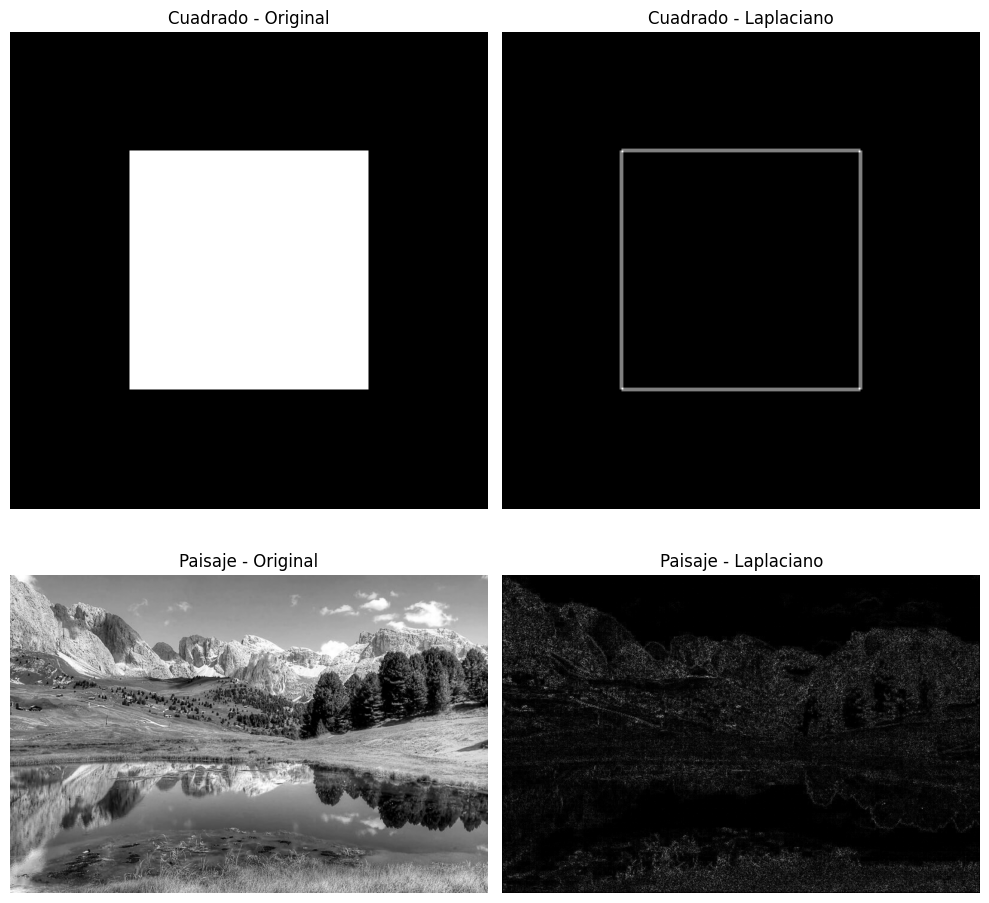

In [46]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos_prewitt, imagenes_prewitt)
):
    respuesta = detectar_bordes_laplaciano(imagen_actual)

    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")
    axs[i, 0].axis("off")

    axs[i, 1].imshow(
        np.abs(respuesta),
        cmap="gray"
    )
    axs[i, 1].set_title(f"{titulo} - Laplaciano")
    axs[i, 1].axis("off")

plt.tight_layout()
plt.savefig("results/deteccion_bordes_laplaciano.png", dpi=300)
plt.show()

### Análisis de resultados — Punto 5: Detección de bordes mediante Laplaciano

Se implementó el operador Laplaciano mediante cuatro ciclos anidados y una máscara espacial de 3×3, que calcula una aproximación de las derivadas de segundo orden. Para visualizar los resultados se utilizó el valor absoluto de las respuestas, considerando que el operador puede producir valores positivos y negativos.

El algoritmo se aplicó a dos imágenes en escala de grises: un cuadrado blanco sobre fondo negro y un paisaje natural.

En la imagen del **cuadrado**, se detectaron correctamente sus cuatro bordes, mientras que el interior y el fondo permanecieron oscuros. Las respuestas se concentraron en las transiciones bruscas entre blanco y negro, generando un contorno fino alrededor de la figura.

En el **paisaje**, se observaron respuestas en los contornos de las montañas, los árboles, la vegetación y los reflejos del agua. Sin embargo, también aparecieron numerosas variaciones pequeñas y texturas, mientras que algunos bordes principales se distinguían con menor claridad.

Este comportamiento ocurre porque el Laplaciano utiliza derivadas de segundo orden, que son sensibles a los cambios locales de intensidad, incluyendo variaciones pequeñas y ruido.

**En conclusión**, el operador Laplaciano permitió detectar los bordes del cuadrado y múltiples detalles del paisaje. Sin embargo, en imágenes naturales puede responder a numerosas texturas y pequeñas variaciones, lo que dificulta identificar algunos contornos principales. Esto demuestra la importancia de considerar un suavizado previo cuando se utilizan derivadas de segundo orden.

## punto 6. 
Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando el algoritmo
de Marr Hildreth. Verificar el funcionamiento con las
mismas imágenes del punto anterior.

In [48]:
def crear_mascara_gaussiana(tamano, sigma):

    if tamano <= 0 or tamano % 2 == 0:
        raise ValueError("El tamaño debe ser impar y positivo.")

    if sigma <= 0:
        raise ValueError("Sigma debe ser positivo.")

    mascara = np.zeros((tamano, tamano), dtype=np.float64)

    radio = tamano // 2

    for i in range(-radio, radio + 1):
        for j in range(-radio, radio + 1):

            mascara[i + radio, j + radio] = np.exp(
                -(i**2 + j**2) / (2 * sigma**2)
            )

    mascara = mascara / np.sum(mascara)

    return mascara

In [49]:
def suavizado_gaussiano(imagen, sigma=2, tamano=5):

    mascara = crear_mascara_gaussiana(tamano, sigma)

    filas, columnas = imagen.shape
    radio = tamano // 2

    imagen_float = imagen.astype(np.float64)

    # Rellenar los bordes replicando sus valores
    extendida = np.pad(
        imagen_float,
        radio,
        mode="edge"
    )

    resultado = np.zeros((filas, columnas), dtype=np.float64)

    for fila in range(filas):
        for columna in range(columnas):

            suma = 0.0

            for i in range(tamano):
                for j in range(tamano):

                    pixel = extendida[fila + i, columna + j]
                    peso = mascara[i, j]

                    suma += pixel * peso

            resultado[fila, columna] = suma

    return resultado

In [50]:
def detectar_cruces_cero(laplaciano, umbral):

    filas, columnas = laplaciano.shape

    bordes = np.zeros(
        (filas, columnas),
        dtype=np.uint8
    )

    for fila in range(1, filas - 1):
        for columna in range(1, columnas - 1):

            centro = laplaciano[fila, columna]

            # Comparar pares opuestos de vecinos
            pares = [
                (laplaciano[fila, columna - 1],
                 laplaciano[fila, columna + 1]),

                (laplaciano[fila - 1, columna],
                 laplaciano[fila + 1, columna]),

                (laplaciano[fila - 1, columna - 1],
                 laplaciano[fila + 1, columna + 1]),

                (laplaciano[fila - 1, columna + 1],
                 laplaciano[fila + 1, columna - 1])
            ]

            for a, b in pares:

                if a * b < 0 and abs(a - b) > umbral:
                    bordes[fila, columna] = 255
                    break

    return bordes

In [51]:
def detectar_bordes_marr_hildreth(
    imagen,
    sigma=2,
    tamano=5,
    umbral=10
):

    if imagen is None:
        raise ValueError("La imagen no se cargó correctamente.")

    # Etapa 1: suavizado Gaussiano
    imagen_suavizada = suavizado_gaussiano(
        imagen,
        sigma=sigma,
        tamano=tamano
    )

    # Etapa 2: Laplaciano
    respuesta_laplaciana = detectar_bordes_laplaciano(
        imagen_suavizada
    )

    # Etapa 3: cruces por cero
    bordes = detectar_cruces_cero(
        respuesta_laplaciana,
        umbral=umbral
    )

    return imagen_suavizada, respuesta_laplaciana, bordes

In [52]:
resultados_marr = {}

for titulo, imagen_actual in zip(
    titulos_prewitt,
    imagenes_prewitt
):

    suavizada, laplaciano, bordes = detectar_bordes_marr_hildreth(
        imagen_actual,
        sigma=2,
        tamano=5,
        umbral=10
    )

    resultados_marr[titulo] = {
        "suavizada": suavizada,
        "laplaciano": laplaciano,
        "bordes": bordes
    }

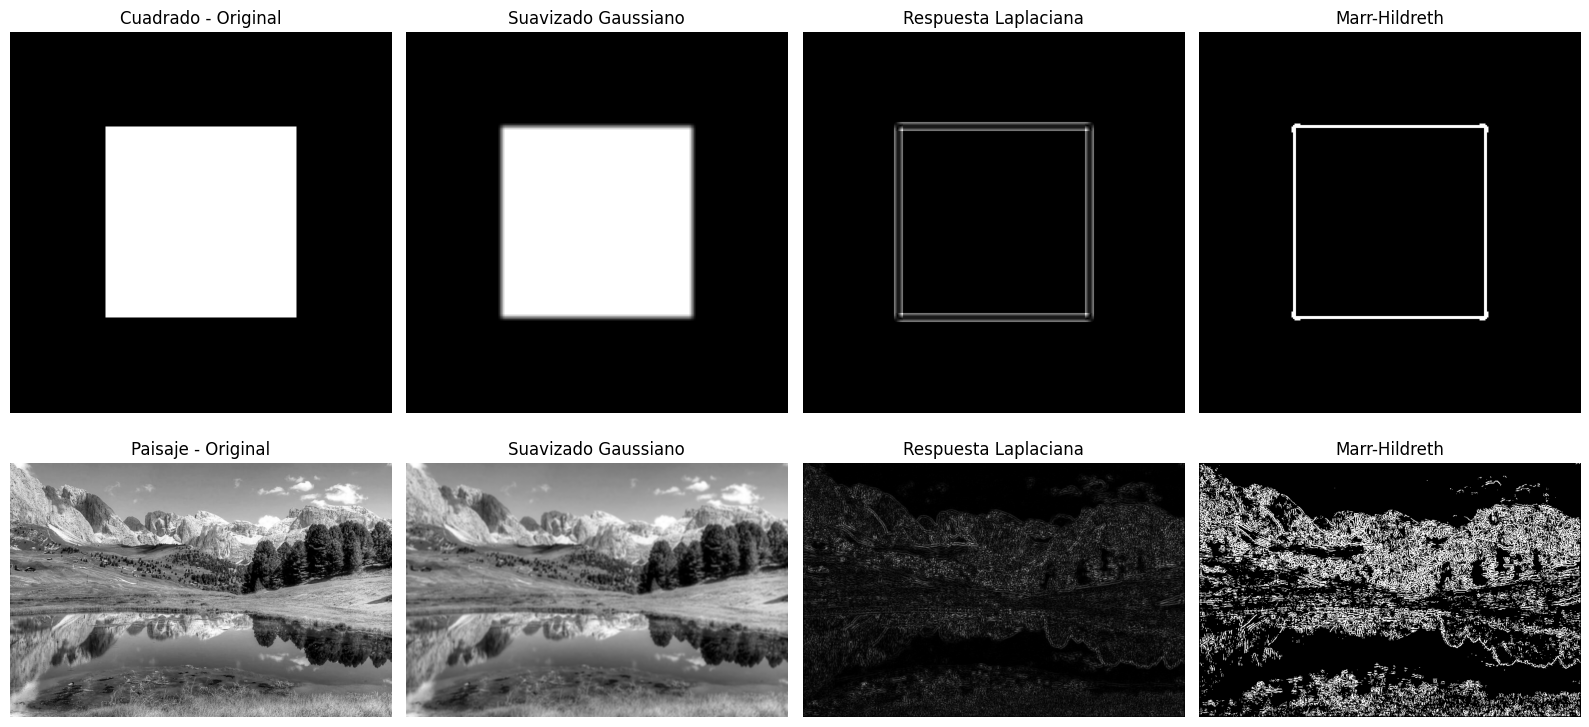

In [53]:
fig, axs = plt.subplots(2, 4, figsize=(16, 8))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos_prewitt, imagenes_prewitt)
):

    resultado = resultados_marr[titulo]

    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")

    axs[i, 1].imshow(
        resultado["suavizada"],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 1].set_title("Suavizado Gaussiano")

    axs[i, 2].imshow(
        np.abs(resultado["laplaciano"]),
        cmap="gray"
    )
    axs[i, 2].set_title("Respuesta Laplaciana")

    axs[i, 3].imshow(
        resultado["bordes"],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 3].set_title("Marr-Hildreth")

    for ax in axs[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(
    "results/deteccion_bordes_marr_hildreth.png",
    dpi=300
)
plt.show()

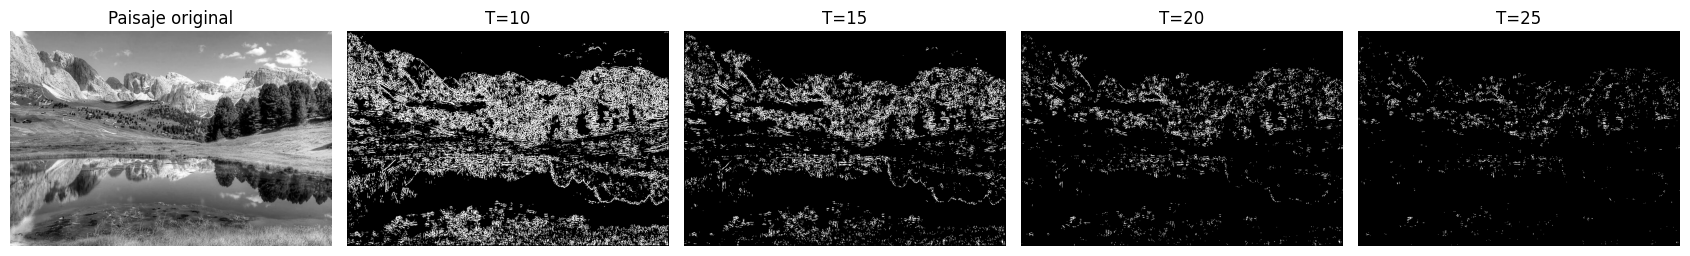

In [55]:
laplaciano_paisaje = resultados_marr["Paisaje"]["laplaciano"]

umbrales = [10, 15, 20, 25]

fig, axs = plt.subplots(1, 5, figsize=(17, 4))

axs[0].imshow(
    paisaje,
    cmap="gray",
    vmin=0,
    vmax=255
)
axs[0].set_title("Paisaje original")
axs[0].axis("off")

for i, umbral in enumerate(umbrales):

    bordes = detectar_cruces_cero(
        laplaciano_paisaje,
        umbral
    )

    axs[i + 1].imshow(
        bordes,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axs[i + 1].set_title(f"T={umbral}")
    axs[i + 1].axis("off")

plt.tight_layout()
plt.savefig(
    "results/marr_hildreth_umbrales_intermedios.png",
    dpi=300
)
plt.show()

### Análisis de resultados — Punto 6: Detección de bordes mediante Marr-Hildreth

Se implementó una versión del algoritmo Marr-Hildreth mediante tres etapas: suavizado Gaussiano, aplicación del operador Laplaciano y detección de cruces por cero. El procedimiento se desarrolló utilizando ciclos y se probó con un cuadrado blanco sobre fondo negro y un paisaje natural.

En la imagen del **cuadrado**, el suavizado Gaussiano redujo la brusquedad de las transiciones entre blanco y negro. Posteriormente, el Laplaciano generó respuestas alrededor de sus límites y la detección de cruces por cero permitió obtener los cuatro contornos, con pequeñas variaciones de grosor en las esquinas.

En el **paisaje**, el algoritmo identificó numerosas variaciones de intensidad en las montañas, los árboles, la vegetación y los reflejos del agua. Sin embargo, con el umbral inicial de 10 se obtuvieron demasiadas detecciones, dificultando distinguir los contornos principales.

Para estudiar este comportamiento se compararon umbrales de 10, 15, 20 y 25. Se observó que al aumentar el umbral disminuía progresivamente la cantidad de respuestas. Con 15 todavía se conservaban varias estructuras reconocibles, mientras que con 20 y 25 algunos contornos comenzaron a perder continuidad.

Para esta imagen se consideró que **T = 15 ofrecía un equilibrio visual razonable** entre la cantidad de detalles detectados y la reducción de respuestas pequeñas.

Los resultados muestran que Marr-Hildreth depende del suavizado Gaussiano y del umbral utilizado para identificar los cruces por cero. En imágenes con numerosas texturas, estos parámetros influyen considerablemente en la cantidad y continuidad de los bordes.

**En conclusión**, el algoritmo permitió identificar correctamente los límites de una figura geométrica y diversas estructuras del paisaje. Sin embargo, no distingue automáticamente entre contornos principales y pequeñas texturas, por lo que es necesario ajustar sus parámetros según las características de la imagen.

## Punto7. 
Desarrollar una función basada en ciclos que permita
detectar bordes en una imagen usando la máscara
Canny. Verificar el funcionamiento con la imagen
"Gwen.pgm" y otras imágenes. Utilizar sigma = 5.

In [56]:
def supresion_no_maximos(magnitud, angulo):

    filas, columnas = magnitud.shape

    resultado = np.zeros(
        (filas, columnas),
        dtype=np.float64
    )

    # Convertir angulos a grados entre 0 y 180
    angulo_grados = np.rad2deg(angulo) % 180

    for fila in range(1, filas - 1):
        for columna in range(1, columnas - 1):

            direccion = angulo_grados[fila, columna]
            actual = magnitud[fila, columna]

            # Direccion 0 grados
            if direccion < 22.5 or direccion >= 157.5:
                vecino1 = magnitud[fila, columna - 1]
                vecino2 = magnitud[fila, columna + 1]

            # Direccion 45 grados
            elif direccion < 67.5:
                vecino1 = magnitud[fila - 1, columna + 1]
                vecino2 = magnitud[fila + 1, columna - 1]

            # Direccion 90 grados
            elif direccion < 112.5:
                vecino1 = magnitud[fila - 1, columna]
                vecino2 = magnitud[fila + 1, columna]

            # Direccion 135 grados
            else:
                vecino1 = magnitud[fila - 1, columna - 1]
                vecino2 = magnitud[fila + 1, columna + 1]

            # Conservar solo maximos locales
            if actual >= vecino1 and actual >= vecino2:
                resultado[fila, columna] = actual

    return resultado

In [58]:
def doble_umbral_histeresis(magnitud, umbral_bajo, umbral_alto):

    if umbral_bajo < 0 or umbral_alto <= umbral_bajo:
        raise ValueError("Los umbrales no son validos.")

    filas, columnas = magnitud.shape

    # Clasificar respuestas
    fuertes = magnitud >= umbral_alto
    debiles = magnitud >= umbral_bajo

    bordes = np.zeros(
        (filas, columnas),
        dtype=np.uint8
    )

    # Lista de puntos fuertes pendientes de revisar
    pendientes = []

    for fila in range(filas):
        for columna in range(columnas):

            if fuertes[fila, columna]:
                bordes[fila, columna] = 255
                pendientes.append((fila, columna))

    # Seguir las conexiones de los bordes fuertes
    while pendientes:

        fila, columna = pendientes.pop()

        for i in range(-1, 2):
            for j in range(-1, 2):

                nueva_fila = fila + i
                nueva_columna = columna + j

                if (
                    0 <= nueva_fila < filas
                    and 0 <= nueva_columna < columnas
                ):
                    if (
                        debiles[nueva_fila, nueva_columna]
                        and bordes[nueva_fila, nueva_columna] == 0
                    ):
                        bordes[nueva_fila, nueva_columna] = 255
                        pendientes.append(
                            (nueva_fila, nueva_columna)
                        )

    return bordes

In [59]:
def detectar_bordes_canny(
    imagen,
    sigma=5,
    umbral_bajo=50,
    umbral_alto=120
):

    if imagen is None:
        raise ValueError("La imagen no se cargo correctamente.")

    # Paso 1: suavizado Gaussiano
    imagen_suavizada = suavizado_gaussiano(
        imagen,
        sigma=sigma,
        tamano=31
    )

    # Paso 2: gradiente mediante Sobel
    magnitud, gx, gy = detectar_bordes_sobel(
        imagen_suavizada
    )

    # Calcular orientacion del gradiente
    angulo = np.arctan2(gy, gx)

    # Paso 3: supresion de no maximos
    magnitud_suprimida = supresion_no_maximos(
        magnitud,
        angulo
    )

    # Paso 4: doble umbral e histeresis
    bordes = doble_umbral_histeresis(
        magnitud_suprimida,
        umbral_bajo,
        umbral_alto
    )

    return (
        imagen_suavizada,
        magnitud,
        magnitud_suprimida,
        bordes
    )

In [60]:
import time

inicio = time.perf_counter()

suavizada, magnitud, suprimida, bordes = detectar_bordes_canny(
    cuadrado,
    sigma=5,
    umbral_bajo=50,
    umbral_alto=120
)

tiempo = time.perf_counter() - inicio

print(f"Tiempo de ejecucion: {tiempo:.2f} segundos")
print("Pixeles detectados:", np.count_nonzero(bordes))

Tiempo de ejecucion: 17.49 segundos
Pixeles detectados: 519


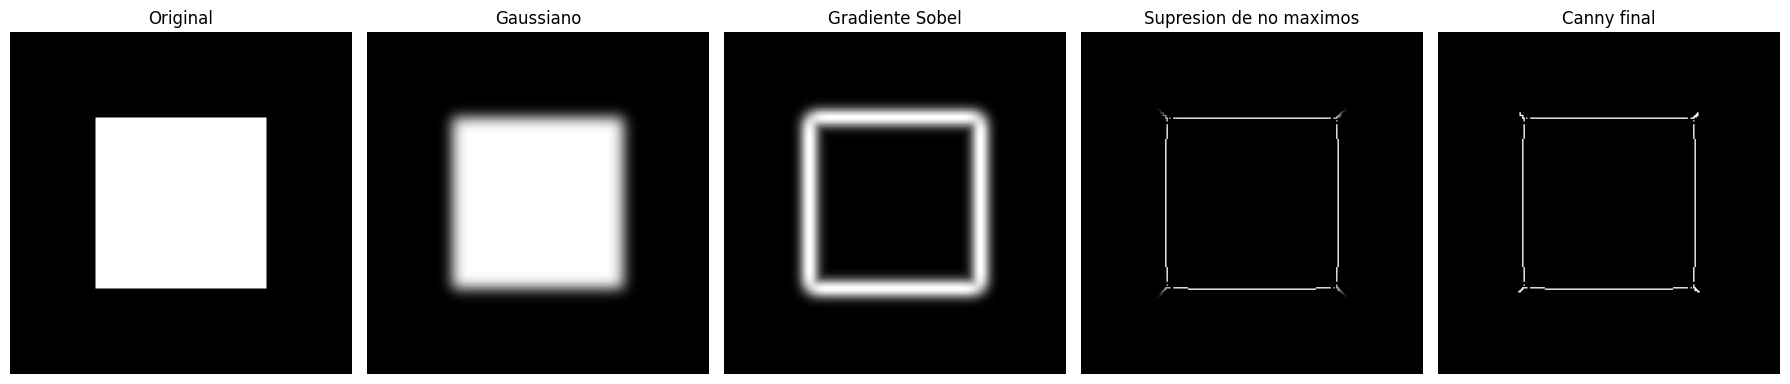

In [61]:
fig, axs = plt.subplots(1, 5, figsize=(18, 4))

imagenes_resultado = [
    cuadrado,
    suavizada,
    magnitud,
    suprimida,
    bordes
]

titulos_resultado = [
    "Original",
    "Gaussiano",
    "Gradiente Sobel",
    "Supresion de no maximos",
    "Canny final"
]

for i, (imagen_actual, titulo) in enumerate(
    zip(imagenes_resultado, titulos_resultado)
):

    if i in (0, 1, 4):
        axs[i].imshow(
            imagen_actual,
            cmap="gray",
            vmin=0,
            vmax=255
        )
    else:
        axs[i].imshow(
            imagen_actual,
            cmap="gray"
        )

    axs[i].set_title(titulo)
    axs[i].axis("off")

plt.tight_layout()

plt.savefig(
    "results/deteccion_bordes_canny_cuadrado.png",
    dpi=300
)

plt.show()

Tiempo de ejecución: 167.63 segundos
Píxeles detectados: 0


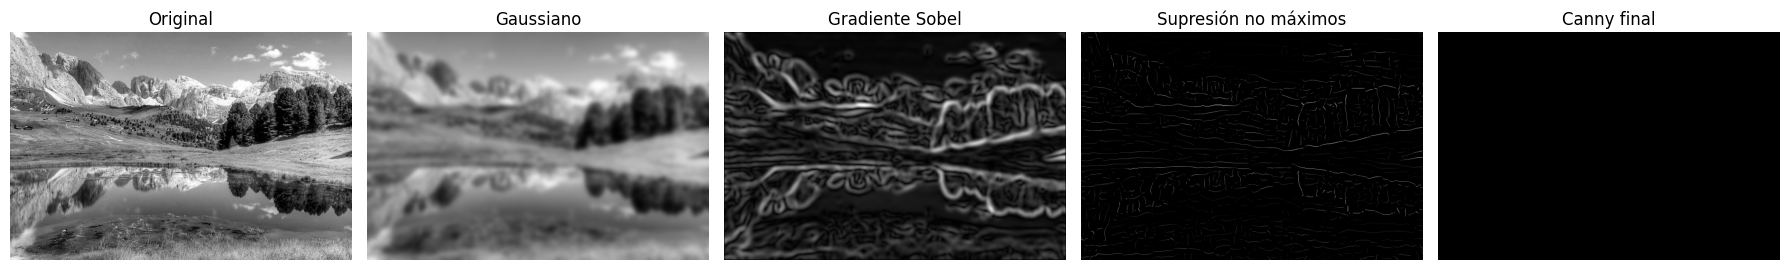

In [62]:
import time

inicio = time.perf_counter()

suavizada, magnitud, suprimida, bordes = detectar_bordes_canny(
    paisaje,
    sigma=5,
    umbral_bajo=50,
    umbral_alto=120
)

tiempo = time.perf_counter() - inicio

print(f"Tiempo de ejecución: {tiempo:.2f} segundos")
print("Píxeles detectados:", np.count_nonzero(bordes))

fig, axs = plt.subplots(1, 5, figsize=(18, 4))

imagenes_resultado = [
    paisaje,
    suavizada,
    magnitud,
    suprimida,
    bordes
]

titulos_resultado = [
    "Original",
    "Gaussiano",
    "Gradiente Sobel",
    "Supresión no máximos",
    "Canny final"
]

for i, (imagen_actual, titulo) in enumerate(
    zip(imagenes_resultado, titulos_resultado)
):

    if i in (0, 1, 4):
        axs[i].imshow(
            imagen_actual,
            cmap="gray",
            vmin=0,
            vmax=255
        )
    else:
        axs[i].imshow(
            imagen_actual,
            cmap="gray"
        )

    axs[i].set_title(titulo)
    axs[i].axis("off")

plt.tight_layout()
plt.savefig(
    "results/deteccion_bordes_canny_paisaje.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Tiempo de ejecución: 87.22 segundos
Píxeles detectados: 10451
Máximo del gradiente: 109.59731152862604
Máximo después de la supresión: 109.59731152862604


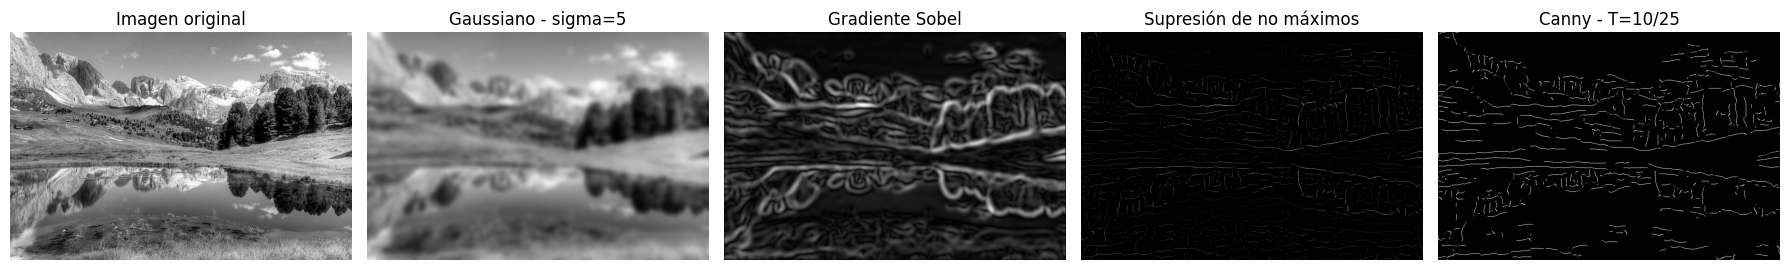

In [67]:
#Cambio de umbrales adecuados
import time

# Parámetros seleccionados
sigma = 5
umbral_bajo = 10
umbral_alto = 25

# Medir tiempo de ejecución
inicio = time.perf_counter()

# Ejecutar todas las etapas de Canny
suavizada, magnitud, suprimida, bordes = detectar_bordes_canny(
    paisaje,
    sigma=sigma,
    umbral_bajo=umbral_bajo,
    umbral_alto=umbral_alto
)

tiempo = time.perf_counter() - inicio

# Mostrar información
print(f"Tiempo de ejecución: {tiempo:.2f} segundos")
print("Píxeles detectados:", np.count_nonzero(bordes))
print("Máximo del gradiente:", np.max(magnitud))
print("Máximo después de la supresión:", np.max(suprimida))

# Visualizar todas las etapas
fig, axs = plt.subplots(1, 5, figsize=(18, 4))

imagenes_resultado = [
    paisaje,
    suavizada,
    magnitud,
    suprimida,
    bordes
]

titulos_resultado = [
    "Imagen original",
    f"Gaussiano - sigma={sigma}",
    "Gradiente Sobel",
    "Supresión de no máximos",
    f"Canny - T={umbral_bajo}/{umbral_alto}"
]

for i, (imagen_actual, titulo) in enumerate(
    zip(imagenes_resultado, titulos_resultado)
):

    if i in (0, 1, 4):
        axs[i].imshow(
            imagen_actual,
            cmap="gray",
            vmin=0,
            vmax=255
        )
    else:
        axs[i].imshow(
            imagen_actual,
            cmap="gray"
        )

    axs[i].set_title(titulo)
    axs[i].axis("off")

plt.tight_layout()

plt.savefig(
    "results/deteccion_bordes_canny_paisaje.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Análisis de resultados — Punto 7: Detección de bordes mediante Canny

Se implementó una versión manual del detector Canny utilizando ciclos y funciones desarrolladas anteriormente. El algoritmo incluyó suavizado Gaussiano con sigma igual a 5, cálculo del gradiente mediante Sobel, supresión de no máximos y doble umbral con histéresis.

Se utilizaron dos imágenes: un cuadrado blanco sobre fondo negro y un paisaje natural.

En la imagen del **cuadrado**, el suavizado Gaussiano hizo que los bordes perdieran definición, mientras que Sobel produjo respuestas gruesas alrededor de sus cuatro lados. Posteriormente, la supresión de no máximos permitió obtener contornos mucho más delgados y la histéresis conservó los bordes principales. Sin embargo, se observaron pequeñas irregularidades en las esquinas debido a las aproximaciones utilizadas para determinar los máximos locales.

En el **paisaje**, el suavizado Gaussiano redujo numerosos detalles de las montañas, los árboles y la vegetación. Después, Sobel resaltó las variaciones de intensidad, generando respuestas relativamente gruesas. La supresión de no máximos permitió adelgazar estas respuestas, aunque algunos contornos quedaron fragmentados.

Inicialmente se utilizaron umbrales de 50 y 120, pero la imagen final quedó completamente negra. Al revisar los valores numéricos, se encontró que la magnitud máxima era aproximadamente 109,60, por lo que ningún píxel alcanzaba el umbral alto de 120.

Para corregirlo, se probaron las combinaciones de umbrales 5–15, 10–25 y 20–50. Se observó que los umbrales bajos permitían conservar numerosas variaciones, mientras que los más altos eliminaban varios contornos.

Finalmente, se seleccionaron **los umbrales 10 y 25**, porque ofrecieron un equilibrio visual razonable entre la cantidad de bordes detectados y la reducción de respuestas pequeñas.

Con esta configuración se conservaron contornos de montañas, árboles, reflejos del agua y algunas estructuras del terreno. Aunque las líneas presentan ciertas interrupciones, se observa claramente la reducción del grosor de las respuestas después de aplicar la supresión de no máximos.

**En conclusión**, Canny permitió identificar bordes mediante varias etapas complementarias. La supresión de no máximos fue importante para obtener contornos más delgados, mientras que la histéresis permitió seleccionar las respuestas según su intensidad y conectividad. Los resultados también demostraron que la elección de los umbrales influye directamente en la cantidad y continuidad de los bordes detectados.